In [1]:
# Import required libraries
import os
os.environ["OMP_NUM_THREADS"] = "1"

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [2]:
# Load Mall Customers dataset
df = pd.read_csv("Mall_Customers - Mall_Customers.csv")

# Display first 5 rows
print("Dataset loaded successfully!")
print(df.head())

Dataset loaded successfully!
   CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40


In [3]:
# Display dataset shape
print("Dataset Shape:", df.shape)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (200, 5)

Missing Values:
CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [4]:
# Select Annual Income and Spending Score
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

# Display selected features
print(X.head())

   Annual Income (k$)  Spending Score (1-100)
0                  15                      39
1                  15                      81
2                  16                       6
3                  16                      77
4                  17                      40


In [5]:
# Standardize the selected features
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [6]:
# Calculate WCSS for different numbers of clusters
wcss = []

for k in range(1, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)

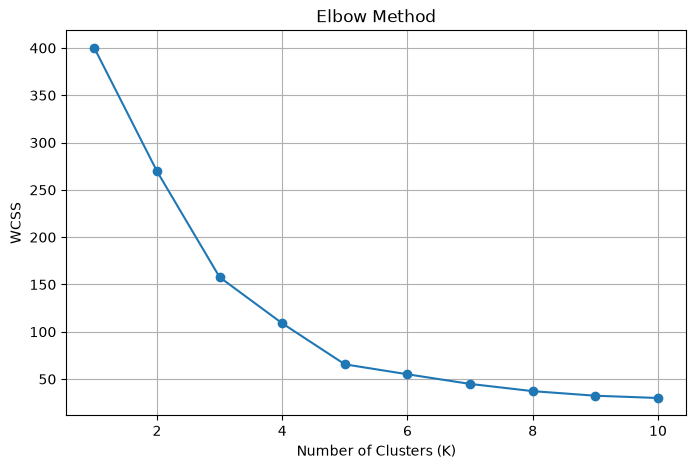

In [7]:
# Visualize the Elbow Method
plt.figure(figsize=(8, 5))

plt.plot(range(1, 11), wcss, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method")

plt.grid(True)
plt.show()

In [8]:
# Select optimal number of clusters
optimal_k = 5

print("Optimal Number of Clusters:", optimal_k)

Optimal Number of Clusters: 5


In [9]:
# Create final K-Means model
kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

# Assign clusters to data points
clusters = kmeans.fit_predict(X_scaled)

In [10]:
# Add cluster labels to original dataset
df["Cluster"] = clusters

# Display clustered data
print("Clustered Data:")
print(df.head(10))

Clustered Data:
   CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)  \
0           1    Male   19                  15                      39   
1           2    Male   21                  15                      81   
2           3  Female   20                  16                       6   
3           4  Female   23                  16                      77   
4           5  Female   31                  17                      40   
5           6  Female   22                  17                      76   
6           7  Female   35                  18                       6   
7           8  Female   23                  18                      94   
8           9    Male   64                  19                       3   
9          10  Female   30                  19                      72   

   Cluster  
0        4  
1        2  
2        4  
3        2  
4        4  
5        2  
6        4  
7        2  
8        4  
9        2  


In [11]:
# Count customers in each cluster
print("Cluster Sizes:")
print(df["Cluster"].value_counts().sort_index())

Cluster Sizes:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


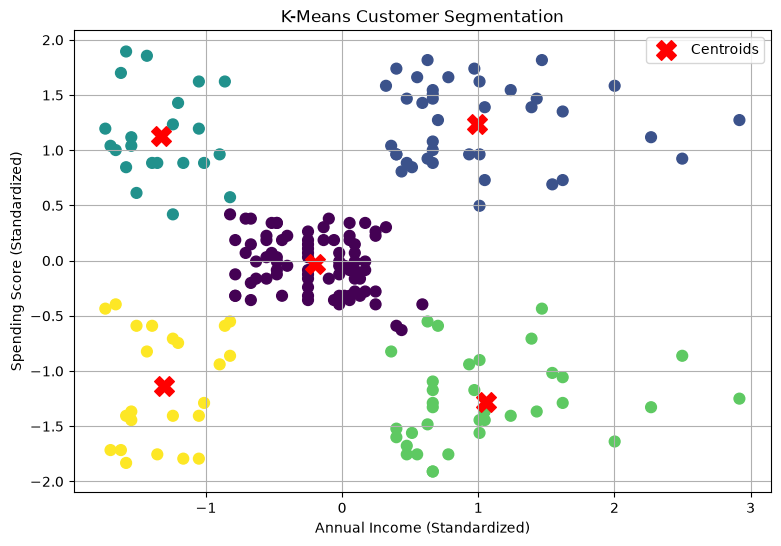

In [12]:
# Plot customer clusters
plt.figure(figsize=(9, 6))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=clusters,
    cmap="viridis",
    s=60
)

# Plot cluster centers
centers = kmeans.cluster_centers_

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    c="red",
    marker="X",
    s=200,
    label="Centroids"
)

plt.xlabel("Annual Income (Standardized)")
plt.ylabel("Spending Score (Standardized)")
plt.title("K-Means Customer Segmentation")

plt.legend()
plt.grid(True)
plt.show()